# Review Evaluation: Products with Iced Level

This notebook evaluates products that have a non-null sweet iced from customer reviews.

In [23]:
import sys
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Add parent directories to path for imports
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

from db.db_azure import connect

# Set display options
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)

# Set plot style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

## 1. Load Reviews with Non-Null Iced Level

In [24]:
# Query to get reviews with non-null sweet level
query = """
SELECT 
    p.id AS product_id,
    p.product_name,
    p.site_name,
    p.site_tag,
    p.brand,
    p.site_category,
    r.id AS review_id,
    r.review_date,
    r.review_text,
    r.rating,
    r.verified,
    case when r.sweet_level is null then 1 else r.sweet_level + 1 end as sweet_level,
    case when r.iced_level is null then 1 else r.iced_level + 1 end as iced_level,
    r.author,
    r.variant
FROM 
    ecig_reviews r
INNER JOIN 
    ecig_product p ON p.id = r.product_id
WHERE 
    (r.sweet_level IS NOT NULL
    or r.iced_level IS NOT NULL)
    AND p.site_name = 'GETPOP'
    AND r.date_inserted < '07-01-2026'
ORDER BY 
    r.date_inserted DESC
"""

# Connect and fetch data
conn = connect()
df_reviews = pd.read_sql(query, conn)
conn.close()

print(f"Total reviews with iced level: {len(df_reviews)}")


/var/folders/r6/bbh6nj696l1_bkjr135f4whj0sdf0t/T/ipykernel_78085/1948481076.py:34: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_reviews = pd.read_sql(query, conn)


Total reviews with iced level: 2422


## 2. Basic Statistics

In [26]:
# Summary statistics
print("Dataset Shape:", df_reviews.shape)
print("\n" + "="*60)
print(f"Unique Products with Iced Level: {df_reviews['product_id'].nunique()}")
print(f"Total Reviews with Iced Level: {len(df_reviews)}")
print(f"Average Reviews per Product: {len(df_reviews) / df_reviews['product_id'].nunique():.2f}")
print("="*60)
print("\Iced Level Statistics:")
print(df_reviews['iced_level'].describe())

Dataset Shape: (2422, 15)

Unique Products with Iced Level: 1083
Total Reviews with Iced Level: 2422
Average Reviews per Product: 2.24
\Iced Level Statistics:
count    2422.000000
mean        2.933113
std         1.520501
min         1.000000
25%         1.000000
50%         3.000000
75%         4.000000
max         5.000000
Name: iced_level, dtype: float64


In [27]:
df_some = df_reviews[df_reviews['iced_level'] > 1]
print(f"Unique Products with Iced Level > 1: {df_some['product_id'].nunique()}")

some = df_some['product_id'].nunique()
all_count = df_reviews['product_id'].nunique()
print(some/all_count, some, all_count)
print("Iced > 1, Dataset Shape:", df_some.shape[0])
print("Iced All, Dataset Shape:", df_reviews.shape[0])
print(df_some.shape[0]/df_reviews.shape[0])

Unique Products with Iced Level > 1: 880
0.8125577100646353 880 1083
Iced > 1, Dataset Shape: 1728
Iced All, Dataset Shape: 2422
0.7134599504541701


Reviews by Site:
site_name
GETPOP    2422
Name: count, dtype: int64


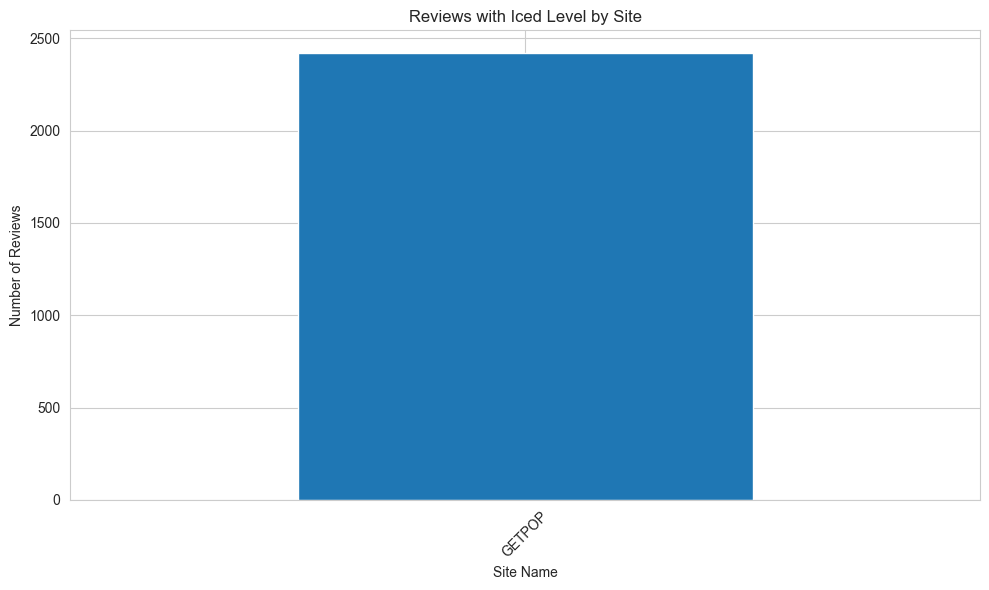

In [28]:
# Distribution by site
print("Reviews by Site:")
site_counts = df_reviews['site_name'].value_counts()
print(site_counts)

# Plot distribution
plt.figure(figsize=(10, 6))
site_counts.plot(kind='bar')
plt.title('Reviews with Iced Level by Site')
plt.xlabel('Site Name')
plt.ylabel('Number of Reviews')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 3. Iced Level Analysis

Iced Level Value Counts:
            count       pct
iced_level                 
1             694  0.286540
2             253  0.104459
3             546  0.225434
4             379  0.156482
5             550  0.227085


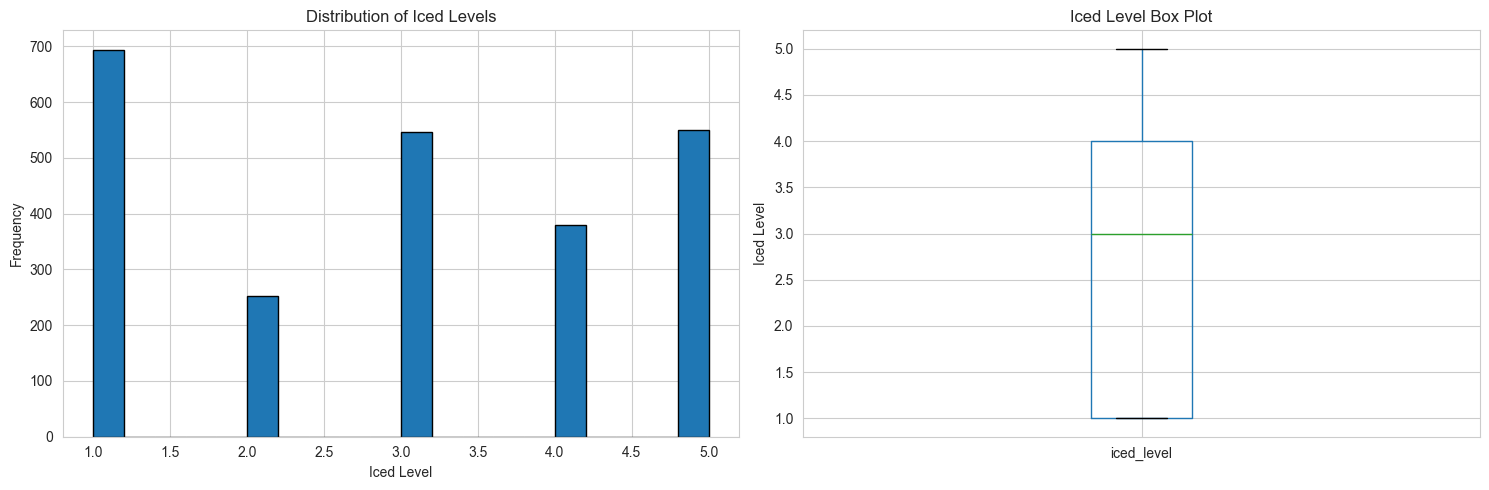

In [29]:
# Sweet level distribution
print("Iced Level Value Counts:")
df_vc = (df_reviews['iced_level'].value_counts().sort_index().to_frame())
df_vc['pct'] = df_vc['count']/df_reviews.shape[0]
print(df_vc)

# Visualize sweet level distribution
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Histogram
df_reviews['iced_level'].hist(bins=20, ax=axes[0], edgecolor='black')
axes[0].set_title('Distribution of Iced Levels')
axes[0].set_xlabel('Iced Level')
axes[0].set_ylabel('Frequency')

# Box plot
df_reviews.boxplot(column='iced_level', ax=axes[1])
axes[1].set_title('Iced Level Box Plot')
axes[1].set_ylabel('Iced Level')

plt.tight_layout()
plt.show()

In [18]:
253+546+379+550

1728

In [30]:
1-0.286540

0.71346

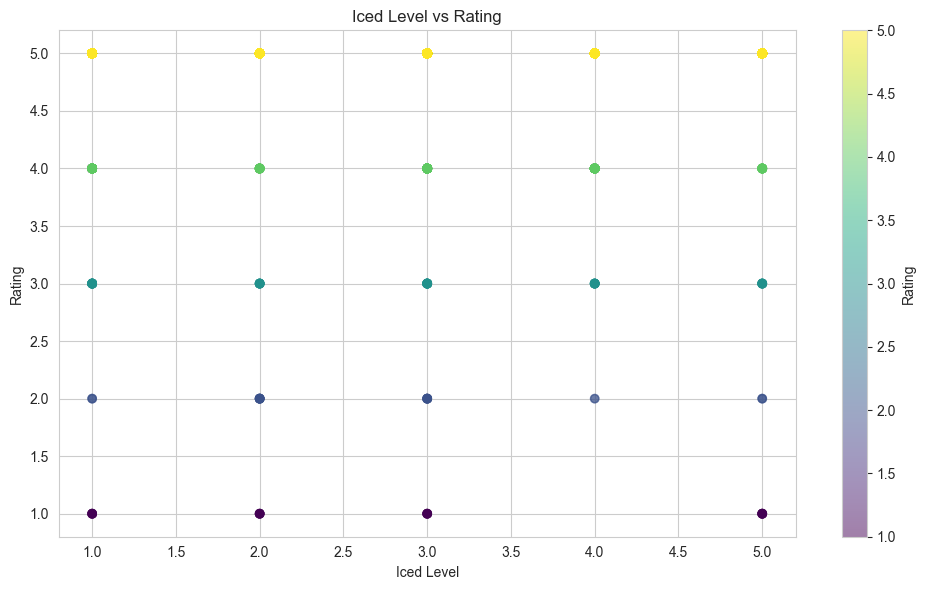


Correlation between Iced Level and Rating:
            iced_level    rating
iced_level    1.000000  0.029506
rating        0.029506  1.000000


In [31]:
# iced level vs Rating correlation
if df_reviews['rating'].notna().sum() > 0:
    fig, ax = plt.subplots(figsize=(10, 6))
    scatter = ax.scatter(df_reviews['iced_level'], df_reviews['rating'], 
                        alpha=0.5, c=df_reviews['rating'], cmap='viridis')
    ax.set_xlabel('Iced Level')
    ax.set_ylabel('Rating')
    ax.set_title('Iced Level vs Rating')
    plt.colorbar(scatter, label='Rating')
    plt.tight_layout()
    plt.show()
    
    # Calculate correlation
    correlation = df_reviews[['iced_level', 'rating']].corr()
    print("\nCorrelation between Iced Level and Rating:")
    print(correlation)

## 4. Product-Level Analysis

In [34]:
df_reviews.head()

,product_id,product_name,site_name,site_tag,brand,site_category,review_id,review_date,review_text,rating,verified,sweet_level,iced_level,author,variant
0,17235,Fifty Bar x Humble 20K Vanilla Tobacco,GETPOP,humble-x-fifty-bar-20k-vanilla-tobacco,None,new-arrivals,60174,2026-06-13,Terrible aftertaste,1.0,True,2,2,Kevin V.,NaN
1,2478,HQD Cuvie Plus Tobacco,GETPOP,hqd-cuvie-plus-tobacco,None,disposables/tobacco,60173,2026-06-14,Love it!!,5.0,True,3,3,Linda m.,NaN
2,13527,Kado Bar Rizz 25K Bomb Pop,GETPOP,kado-bar-rizz-25k-bomb-pop,None,disposables,60172,2026-06-20,One of my favs!,5.0,True,3,4,Tara P.,NaN
3,9784,Kado Bar NI40K Sour-Nic Control Sour Apple Hard Candy,GETPOP,kado-bar-ni40k-sour-nic-control-sour-apple-hard-candy,None,disposables,60171,2026-06-21,My favorite vape. Just the right amount of sour and love you can control the sourness and the ni...,5.0,True,5,5,Jordan S.,NaN
4,3579,Geek Bar Pulse 15000 Sour Gush (Cherry Raspberry Lime),GETPOP,geek-bar-pulse-15000-sour-gush,None,disposables/geek-bar,60170,2026-06-23,It has a sour tangy taste with some cherry to it. It is one of my favorites absolutely love. One...,5.0,True,5,5,Christina C.,NaN


In [43]:
# Aggregate by product
product_summary = df_reviews.groupby(['product_id', 'product_name']).agg({
    'iced_level': ['mean', 'std', 'min', 'max', 'count'],
    'rating': ['mean', 'count'],
    'iced_level': 'mean'
}).round(2)

product_summary.columns


MultiIndex([('iced_level',  'mean'),
            (    'rating',  'mean'),
            (    'rating', 'count')],
           )

In [44]:
#product_summary.columns = ['_'.join(col).strip() for col in product_summary.columns.values]
product_summary.columns = [f"{a}_{b}" if b else f"{a}" for a, b in product_summary.columns]
product_summary = product_summary.reset_index()
product_summary = product_summary.sort_values('rating_count', ascending=False)

print(f"Total products with iced level reviews: {len(product_summary)}")
print("\nTop 10 Products by Number of Iced Level Reviews:")
product_summary.head(10)

Total products with iced level reviews: 1083

Top 10 Products by Number of Iced Level Reviews:


,product_id,product_name,iced_level_mean,rating_mean,rating_count
232,3035,Fifty Bar 20K Vanilla Custard,1.71,4.86,21
11,1852,Hyde Edge Recharge Minty O's,4.50,4.85,20
19,1885,Hyde Edge Recharge Spearmint,3.28,5.00,18
166,2487,RAZ LTX 25K Tobacco,2.47,4.82,17
233,3037,Fume Ultra 2500 Mint Ice,4.53,4.93,15
210,2932,Hyde Edge Recharge Blue Razz,2.07,5.00,14
383,3461,Fifty Bar 20K Cinnamon Funnel Cake,1.86,5.00,14
241,3054,EB Design BC5000 Miami Mint,4.21,4.86,14
136,2370,HQD Cuvie Plus 2.0 Colombian Coffee Ice,3.54,4.77,13
13,1864,Hyde Edge Recharge Peach Mango Watermelon,1.00,5.00,13


In [47]:
# Products with highest average sweet level (min 5 reviews)
high_iced = product_summary[product_summary['rating_count'] >= 5].sort_values(
    'iced_level_mean', ascending=False
).head(10)

print("Top 10 Iciest Products (min 5 reviews):")
print(high_iced[['product_name', 'iced_level_mean', 'rating_count', 'rating_mean']])

Top 10 Iciest Products (min 5 reviews):
                                                 product_name  \
351                   Kado Bar NI40K Ice-Nic Control Bomb Pop   
239                                          STIG Mighty Mint   
478                       Lost Mary MT15000 Turbo Winter Mint   
143                              HQD Cuvie Bar 7000 Cool Mint   
235               Hyppe Max Flow Mighty Mint / Mighty Menthol   
24                                 Fume Ultra 2500 Banana Ice   
494                        Lost Mary OS5000 Banana Duo Ice 5%   
233                                  Fume Ultra 2500 Mint Ice   
11                               Hyde Edge Recharge Minty O's   
923  Kado Bar NI40K Ice-Nic Control Strawberry Watermelon Ice   

     iced_level_mean  rating_count  rating_mean  
351             5.00             7         5.00  
239             4.80             5         5.00  
478             4.80             5         5.00  
143             4.75             8         5

## 5. Brand Analysis

## 6. Sweet vs Iced Relationship

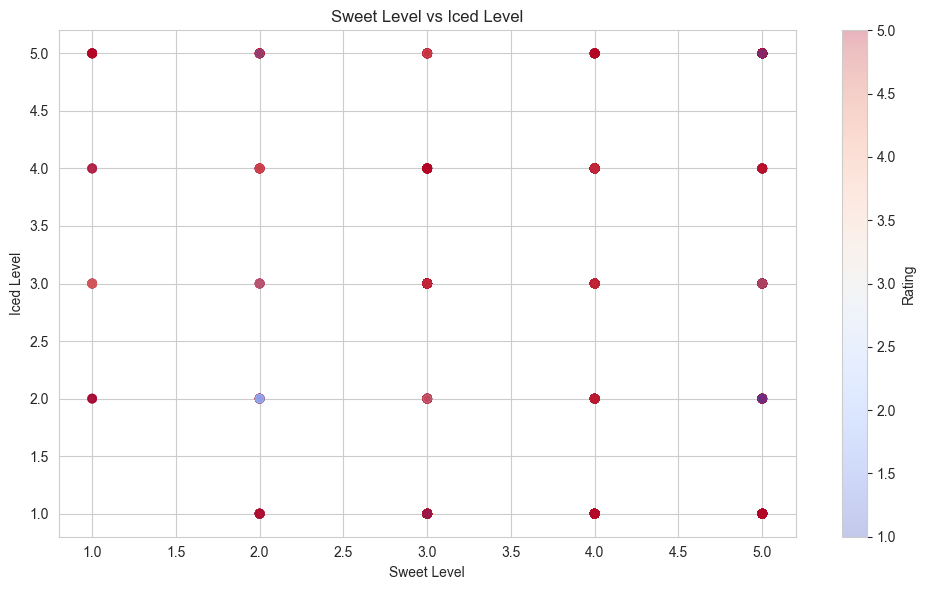


Correlation between Sweet Level and Iced Level:
             sweet_level  iced_level
sweet_level     1.000000    0.100261
iced_level      0.100261    1.000000


In [48]:
# Compare sweet and iced levels
if df_reviews['iced_level'].notna().sum() > 0:
    fig, ax = plt.subplots(figsize=(10, 6))
    scatter = ax.scatter(df_reviews['sweet_level'], df_reviews['iced_level'], 
                        alpha=0.3, c=df_reviews['rating'], cmap='coolwarm')
    ax.set_xlabel('Sweet Level')
    ax.set_ylabel('Iced Level')
    ax.set_title('Sweet Level vs Iced Level')
    plt.colorbar(scatter, label='Rating')
    plt.tight_layout()
    plt.show()
    
    # Correlation
    if df_reviews['iced_level'].notna().sum() > 1:
        correlation = df_reviews[['sweet_level', 'iced_level']].corr()
        print("\nCorrelation between Sweet Level and Iced Level:")
        print(correlation)

## 7. Sample Review Text Analysis

In [51]:
# Show examples of high sweet level reviews
high_iced_reviews = df_reviews.nlargest(5, 'iced_level')[[
    'product_name', 'iced_level', 'rating', 'review_text'
]]

print("Sample High Iced Level Reviews:\n")
for idx, row in high_iced_reviews.iterrows():
    print(f"Product: {row['product_name']}")
    print(f"Iced Level: {row['iced_level']} | Rating: {row['rating']}")
    print(f"Review: {row['review_text'][:200]}...")
    print("-" * 80)
    print()

Sample High Iced Level Reviews:

Product: Kado Bar NI40K Sour-Nic Control Sour Apple Hard Candy
Iced Level: 5 | Rating: 5.0
Review: My favorite vape. Just the right amount of sour and love you can control the sourness and the nicotine level...
--------------------------------------------------------------------------------

Product: Geek Bar Pulse 15000 Sour Gush (Cherry Raspberry Lime)
Iced Level: 5 | Rating: 5.0
Review: It has a sour tangy taste with some cherry to it. It is one of my favorites absolutely love. One of the two that I buy....
--------------------------------------------------------------------------------

Product: Off-Stamp Ice Cube Pod Blue Razz Dragonfruit
Iced Level: 5 | Rating: 5.0
Review: Favorite one !!...
--------------------------------------------------------------------------------

Product: Cali XLT 40K Frozen Grape
Iced Level: 5 | Rating: 5.0
Review: Grape is fantastic...
--------------------------------------------------------------------------------

Pro

In [53]:
# Show examples of low sweet level reviews
low_iced_reviews = df_reviews.nsmallest(5, 'iced_level')[[
    'product_name', 'iced_level', 'rating', 'review_text'
]]

print("Sample Low iced Level Reviews:\n")
for idx, row in low_iced_reviews.iterrows():
    print(f"Product: {row['product_name']}")
    print(f"Iced Level: {row['iced_level']} | Rating: {row['rating']}")
    print(f"Review: {row['review_text'][:200]}...")
    print("-" * 80)
    print()

Sample Low iced Level Reviews:

Product: RAZ VUE 50K Pod White Gummy
Iced Level: 1 | Rating: 5.0
Review: sweet...
--------------------------------------------------------------------------------

Product: RAZ TN9000 Strawberry Shortcake
Iced Level: 1 | Rating: 5.0
Review: This is sweet to the end....
--------------------------------------------------------------------------------

Product: EB Create BC5000 Pineapple Punch
Iced Level: 1 | Rating: 5.0
Review: This ones a winner!...
--------------------------------------------------------------------------------

Product: Geek Bar Pulse 15000 Sour Blue Dust
Iced Level: 1 | Rating: 5.0
Review: A burst of sour blue raspberry. Sweet and sour...
--------------------------------------------------------------------------------

Product: Fume Ultra 2500 Rainbow Candy
Iced Level: 1 | Rating: 5.0
Review: Yummy...
--------------------------------------------------------------------------------



## 8. Export Results

In [54]:
# Export product summary to CSV
output_dir = 'nlp/reviews/results'
os.makedirs(output_dir, exist_ok=True)

product_summary.to_csv(f'{output_dir}/iced_level_product_summary.csv', index=False)
df_reviews.to_csv(f'{output_dir}/iced_level_reviews_full.csv', index=False)

print(f"Results exported to {output_dir}/")
print(f"- iced_level_product_summary.csv ({len(product_summary)} products)")
print(f"- iced_level_reviews_full.csv ({len(df_reviews)} reviews)")

Results exported to nlp/reviews/results/
- iced_level_product_summary.csv (1083 products)
- iced_level_reviews_full.csv (2422 reviews)
